<a href="https://colab.research.google.com/github/nanditanair05-byte/intermediate_assesment_3/blob/main/intermediate_assesment_3_nandita.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#1. Import libraries
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    f1_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, make_scorer
)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    GradientBoostingClassifier, HistGradientBoostingClassifier,
    VotingClassifier
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Load the training data

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Read the training dataset from Google Drive
TRAIN_PATH = '/content/drive/MyDrive/DSA/kaggle casestudy dataset/train.csv'

train_df = pd.read_csv(TRAIN_PATH)

# Display the dataset
print("Dataset shape:", train_df.shape)
display(train_df.head())


Dataset shape: (94, 14)


,id,sexo,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
0,0J4_2016,H,174.18,106.85,80.19,52.43,30.20,23.26,88.74,51.0,95.7,104.2,208.4,2.38
1,A68_2016,H,171.12,104.59,79.45,51.14,30.61,24.04,90.22,50.5,94.4,102.2,204.4,2.14
2,E55_2015,H,174.69,106.83,82.14,49.09,30.60,26.47,91.42,52.7,96.6,105.2,210.4,2.50
3,7C7_2016,M,182.25,113.17,84.13,52.26,32.08,26.07,91.74,52.6,98.9,107.6,215.2,2.83
4,2C0_2018,H,173.70,105.19,80.37,49.20,34.00,27.12,87.77,50.8,94.5,103.7,207.4,2.73


In [ ]:

print("Shape:", train_df.shape)
display(train_df.head())
display(train_df.dtypes.to_frame("dtype"))

Shape: (94, 14)


,id,sexo,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
0,0J4_2016,H,174.18,106.85,80.19,52.43,30.20,23.26,88.74,51.0,95.7,104.2,208.4,2.38
1,A68_2016,H,171.12,104.59,79.45,51.14,30.61,24.04,90.22,50.5,94.4,102.2,204.4,2.14
2,E55_2015,H,174.69,106.83,82.14,49.09,30.60,26.47,91.42,52.7,96.6,105.2,210.4,2.50
3,7C7_2016,M,182.25,113.17,84.13,52.26,32.08,26.07,91.74,52.6,98.9,107.6,215.2,2.83
4,2C0_2018,H,173.70,105.19,80.37,49.20,34.00,27.12,87.77,50.8,94.5,103.7,207.4,2.73


,dtype
id,object
sexo,object
longitudCraneo,float64
longitudPico,float64
longitudNarina,float64
anchoCraneo,float64
altoPico,float64
anchoPico,float64
tarso,float64
longAlaCerrada,float64


## 3. Initial inspection and data quality

In [ ]:
print("Rows, columns:", train_df.shape)
print("\nColumn names:\n", train_df.columns.tolist())
print("\nData types:")
display(train_df.dtypes.to_frame("dtype"))
print("\nMissing values:")
missing = pd.DataFrame({
    "missing_count": train_df.isna().sum(),
    "missing_percent": (train_df.isna().mean() * 100).round(2)
})
display(missing)
print("\nExact duplicate rows:", train_df.duplicated().sum())
print("Duplicate IDs:", train_df["id"].duplicated().sum() if "id" in train_df else "id column missing")
print("\nTarget counts:")
display(train_df["sexo"].value_counts(dropna=False).to_frame("count"))
print("\nTarget percentages:")
display((train_df["sexo"].value_counts(normalize=True, dropna=False) * 100).round(2).to_frame("percent"))

Rows, columns: (94, 14)

Column names:
 ['id', 'sexo', 'longitudCraneo', 'longitudPico', 'longitudNarina', 'anchoCraneo', 'altoPico', 'anchoPico', 'tarso', 'longAlaCerrada', 'longAlaAbierta', 'mediaEnvergadura', 'envergadura', 'peso']

Data types:


,dtype
id,object
sexo,object
longitudCraneo,float64
longitudPico,float64
longitudNarina,float64
anchoCraneo,float64
altoPico,float64
anchoPico,float64
tarso,float64
longAlaCerrada,float64



Missing values:


,missing_count,missing_percent
id,0,0.00
sexo,0,0.00
longitudCraneo,0,0.00
longitudPico,0,0.00
longitudNarina,0,0.00
anchoCraneo,0,0.00
altoPico,0,0.00
anchoPico,0,0.00
tarso,0,0.00
longAlaCerrada,0,0.00



Exact duplicate rows: 0
Duplicate IDs: 0

Target counts:


,count
sexo,
H,57
M,37



Target percentages:


,percent
sexo,
H,60.64
M,39.36


In [ ]:
# Summary statistics
display(train_df.describe())

# Check target labels
print("Target labels:", train_df["sexo"].unique())

# Check unique IDs
print("Unique IDs:", train_df["id"].nunique())

,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
count,94.000000,94.000000,94.000000,94.000000,94.000000,94.000000,94.00000,94.000000,94.000000,94.000000,94.000000,93.000000
mean,176.580106,110.130426,82.936383,52.687553,32.535000,25.425319,90.88766,51.667021,96.259043,104.765213,209.530426,2.624516
std,5.443278,4.028920,3.187515,2.226749,1.383418,1.439065,2.85098,1.185340,2.187660,2.486498,4.972997,0.315968
min,165.580000,102.710000,74.820000,46.500000,29.340000,21.480000,84.04000,48.700000,88.900000,99.300000,198.600000,2.030000
25%,172.187500,106.835000,80.217500,51.207500,31.605000,24.500000,88.66000,51.000000,94.725000,103.175000,206.350000,2.400000
50%,176.915000,110.070000,83.325000,52.475000,32.605000,25.480000,91.03500,51.600000,96.500000,104.950000,209.900000,2.600000
75%,180.525000,113.252500,85.425000,54.347500,33.460000,26.372500,92.57000,52.475000,97.875000,106.550000,213.100000,2.830000
max,191.210000,119.480000,90.680000,58.360000,35.500000,28.700000,99.69000,54.700000,101.300000,112.200000,224.400000,3.530000


Target labels: ['H' 'M']
Unique IDs: 94


## 4. Exploratory Data Analysis (EDA)

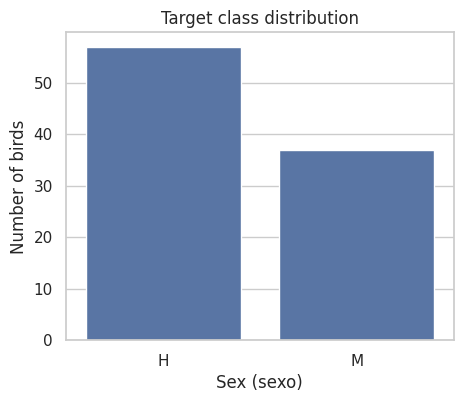

In [ ]:
# Target balance
plt.figure(figsize=(5, 4))
sns.countplot(data=train_df, x="sexo", order=train_df["sexo"].value_counts().index)
plt.title("Target class distribution")
plt.xlabel("Sex (sexo)")
plt.ylabel("Number of birds")
plt.show()

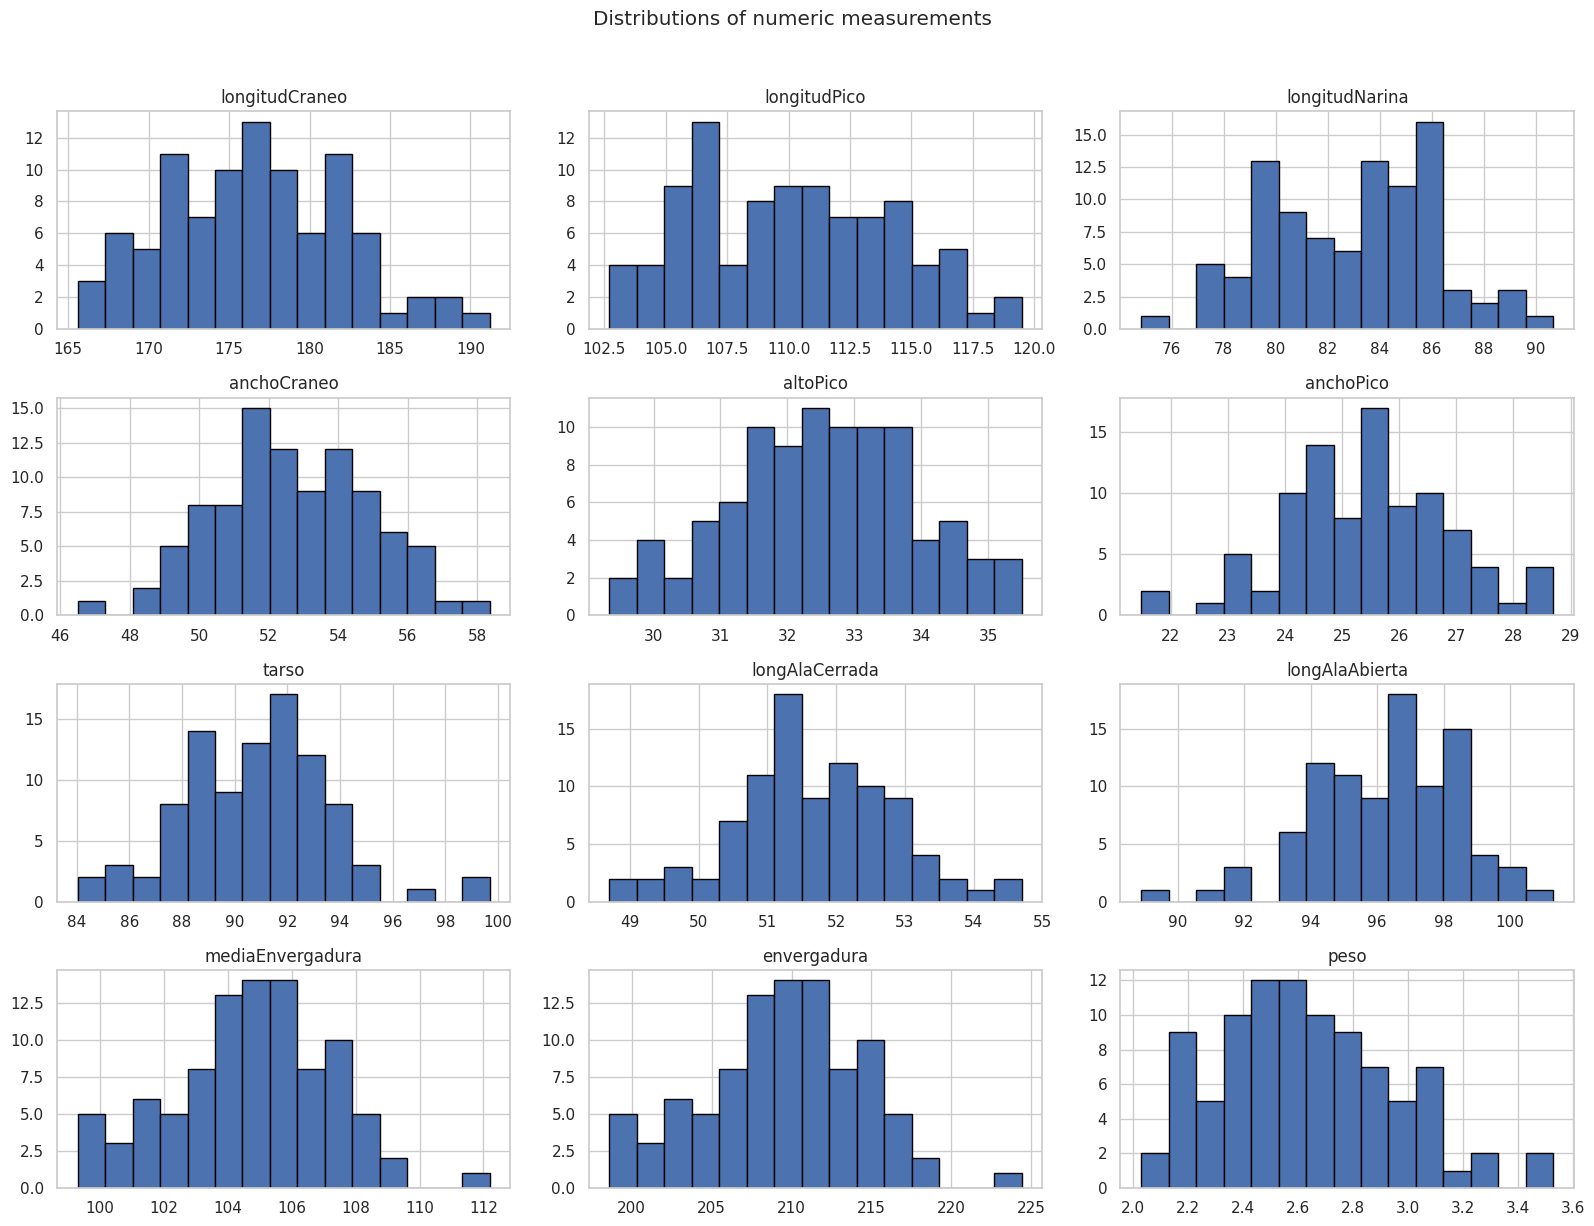

In [ ]:
numeric_cols = train_df.select_dtypes(include=np.number).columns.tolist()
train_df[numeric_cols].hist(figsize=(16, 12), bins=15, edgecolor="black")
plt.suptitle("Distributions of numeric measurements", y=1.02)
plt.tight_layout()
plt.show()

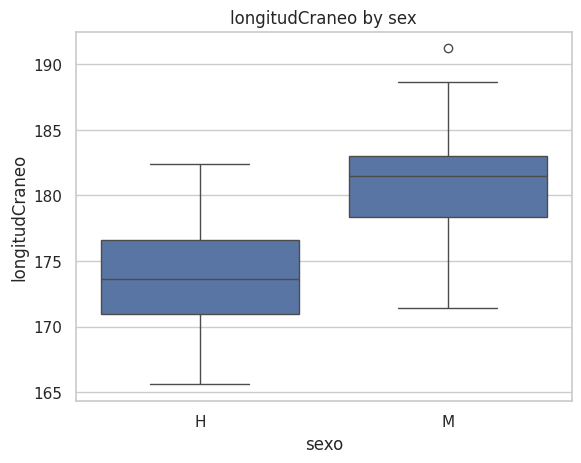

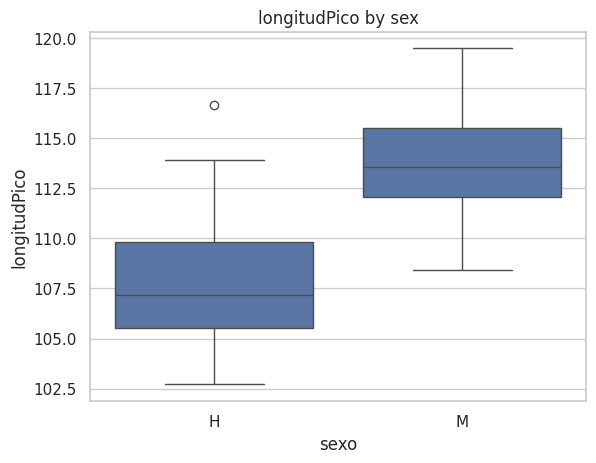

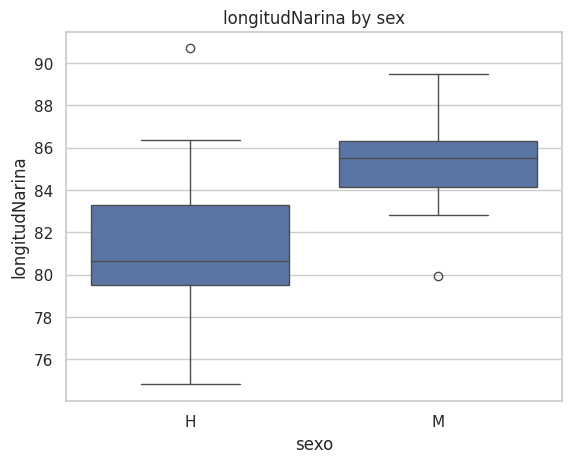

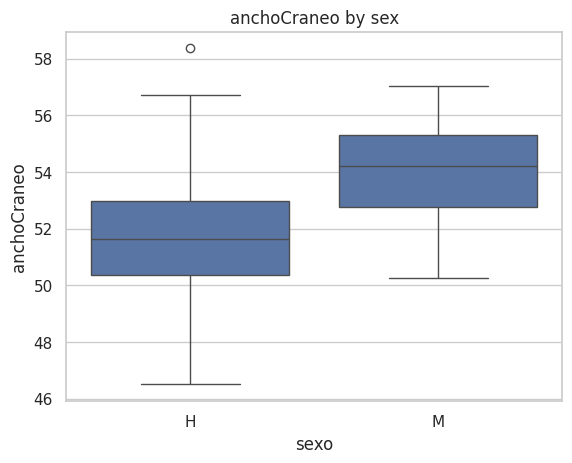

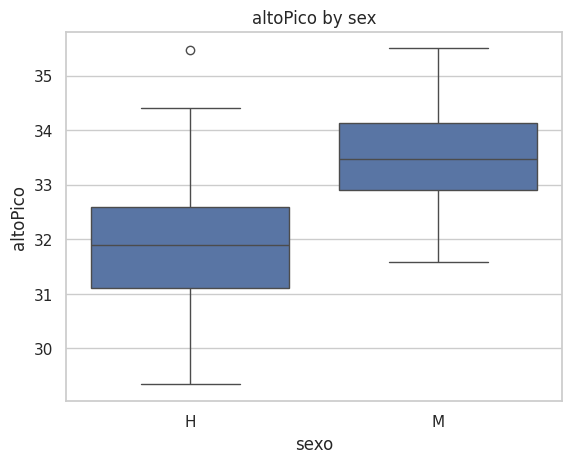

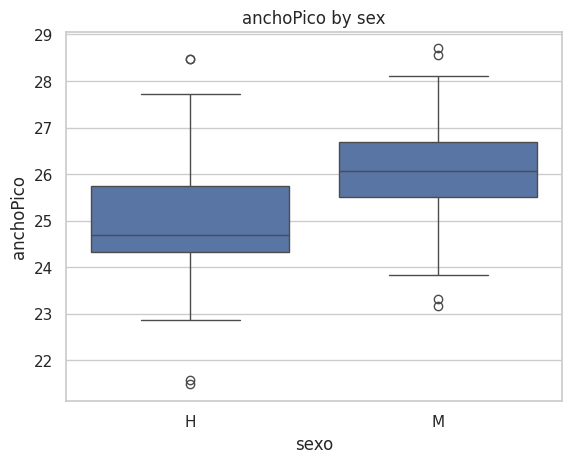

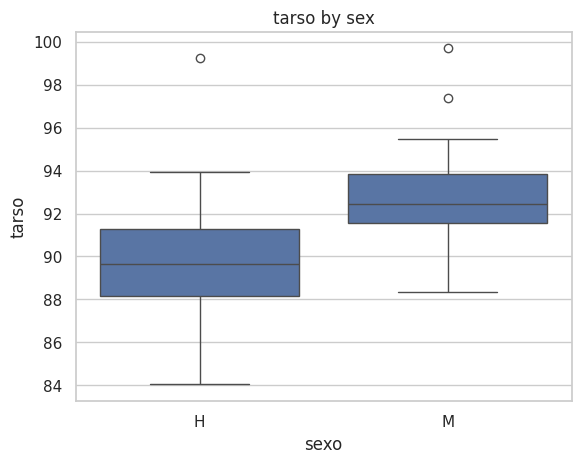

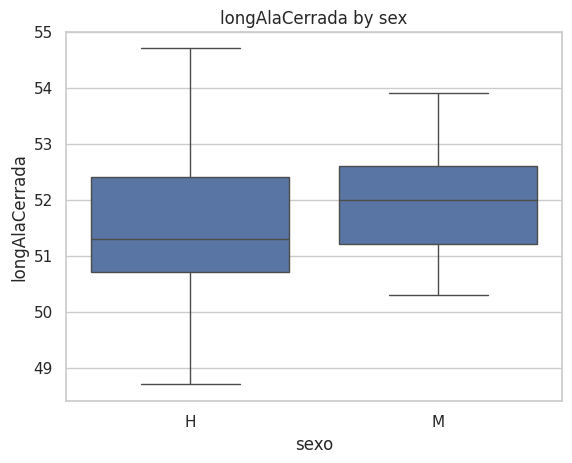

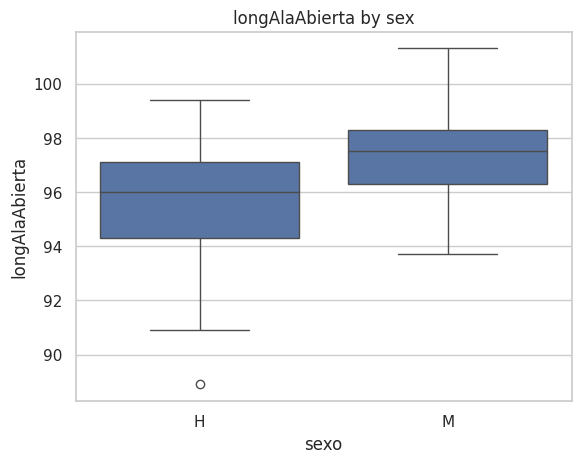

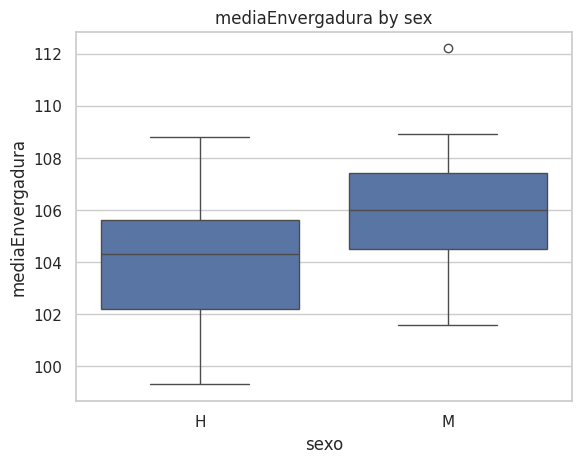

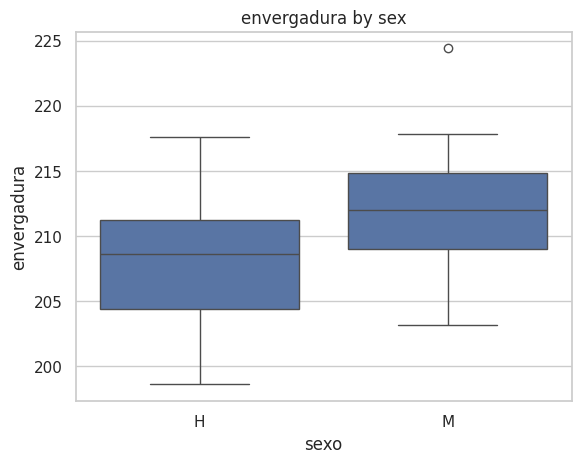

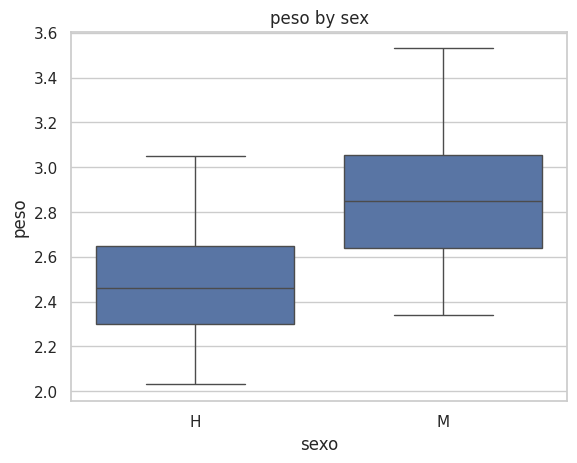

In [ ]:
# Compare measurements by sex using boxplots
for col in train_df.select_dtypes(include='number').columns:
    if col != 'id':
        sns.boxplot(data=train_df, x='sexo', y=col)
        plt.title(f'{col} by sex')
        plt.show()

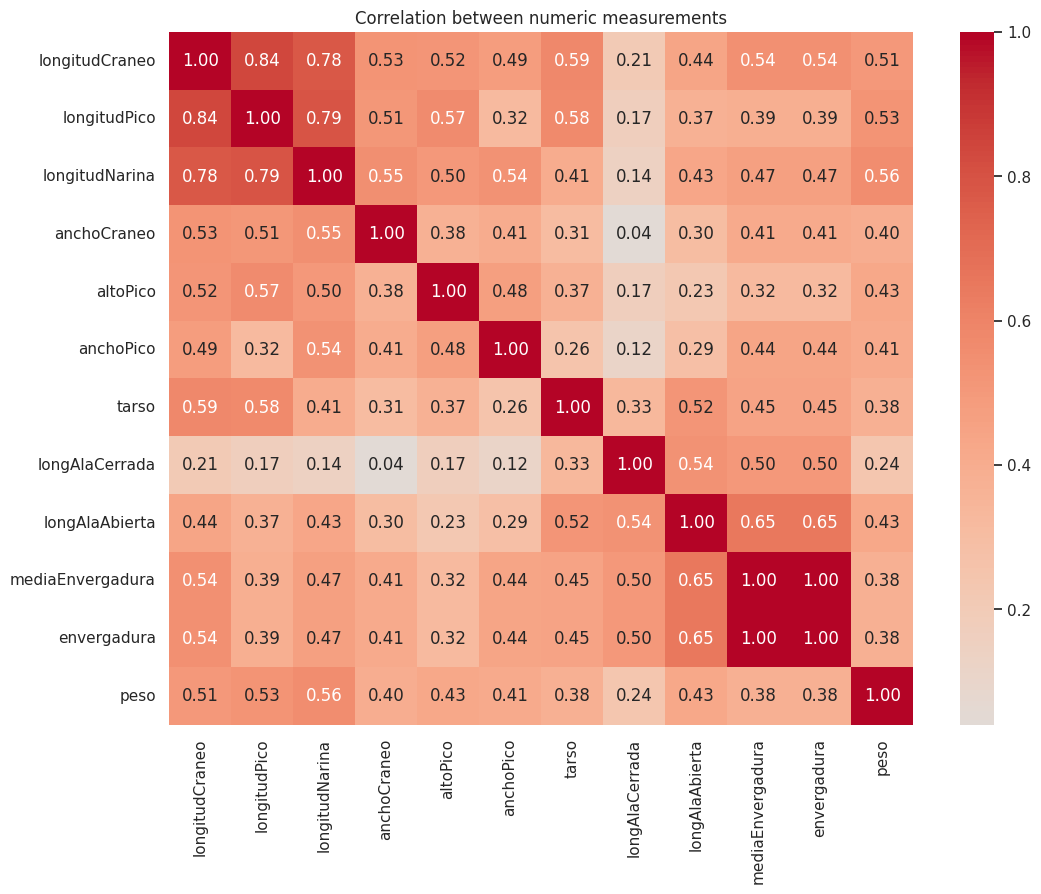

In [ ]:
# Correlation heatmap: numeric features only (target is categorical)
corr_cols = [c for c in numeric_cols if c != "id"]
plt.figure(figsize=(12, 9))
sns.heatmap(train_df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numeric measurements")
plt.show()

## 5. Data quality and measurement checks

In [ ]:
# Check wingspan measurements
train_df['difference'] = train_df['envergadura'] - 2 * train_df['mediaEnvergadura']

display(train_df['difference'].describe())

# Count rows with a difference greater than 0.1
print("Inconsistent rows:", (train_df['difference'].abs() > 0.1).sum())

,difference
count,94.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0


Inconsistent rows: 0


In [ ]:
# Select numeric columns, excluding id
cols = train_df.select_dtypes(include='number').columns.drop('id', errors='ignore')

# Convert selected columns to numeric
train_df[cols] = train_df[cols].apply(pd.to_numeric, errors='coerce')
# Count zero and negative values
print("Zero or negative values:")
print((train_df[cols] <= 0).sum())

# Display rows with missing or non-positive measurements
problem_rows = train_df[train_df[cols].isna().any(axis=1) | (train_df[cols] <= 0).any(axis=1)]

display(problem_rows)

Zero or negative values:
longitudCraneo       0
longitudPico         0
longitudNarina       0
anchoCraneo          0
altoPico             0
anchoPico            0
tarso                0
longAlaCerrada       0
longAlaAbierta       0
mediaEnvergadura     0
envergadura          0
peso                 0
difference          94
dtype: int64


,id,sexo,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso,difference
0,0J4_2016,H,174.18,106.85,80.19,52.43,30.20,23.26,88.74,51.0,95.7,104.2,208.4,2.38,0.0
1,A68_2016,H,171.12,104.59,79.45,51.14,30.61,24.04,90.22,50.5,94.4,102.2,204.4,2.14,0.0
2,E55_2015,H,174.69,106.83,82.14,49.09,30.60,26.47,91.42,52.7,96.6,105.2,210.4,2.50,0.0
3,7C7_2016,M,182.25,113.17,84.13,52.26,32.08,26.07,91.74,52.6,98.9,107.6,215.2,2.83,0.0
4,2C0_2018,H,173.70,105.19,80.37,49.20,34.00,27.12,87.77,50.8,94.5,103.7,207.4,2.73,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89,H50_2017,H,168.18,106.70,80.30,49.20,31.30,24.50,91.30,53.4,98.6,105.9,211.8,2.73,0.0
90,3C0_2015,H,173.95,106.88,81.77,50.27,32.54,25.65,88.64,52.4,96.0,105.9,211.8,2.65,0.0
91,A62_2016,M,181.01,109.98,82.95,55.47,32.84,25.84,90.78,51.4,96.0,105.4,210.8,2.55,0.0
92,H24_2015,M,181.51,112.57,85.58,54.11,32.60,26.02,93.11,53.0,98.0,107.4,214.8,3.10,0.0


## 6. Feature engineering


In [ ]:
# Create new features
train_fe = train_df.copy()

train_fe['beak_to_skull_ratio'] = train_fe['longitudPico'] / train_fe['longitudCraneo']

train_fe['beak_height_ratio'] = train_fe['altoPico'] / train_fe['longitudPico']

train_fe['beak_width_ratio'] = train_fe['anchoPico'] / train_fe['longitudPico']

train_fe['wing_ratio'] = train_fe['longAlaAbierta'] / train_fe['longAlaCerrada']

train_fe['mass_to_skull_ratio'] = train_fe['peso'] / train_fe['longitudCraneo']

print("Original shape:", train_df.shape)
print("New shape:", train_fe.shape)

display(train_fe.head())

Original shape: (94, 15)
New shape: (94, 20)


,id,sexo,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso,difference,beak_to_skull_ratio,beak_height_ratio,beak_width_ratio,wing_ratio,mass_to_skull_ratio
0,0J4_2016,H,174.18,106.85,80.19,52.43,30.20,23.26,88.74,51.0,95.7,104.2,208.4,2.38,0.0,0.613446,0.282639,0.217688,1.876471,0.013664
1,A68_2016,H,171.12,104.59,79.45,51.14,30.61,24.04,90.22,50.5,94.4,102.2,204.4,2.14,0.0,0.611209,0.292667,0.229850,1.869307,0.012506
2,E55_2015,H,174.69,106.83,82.14,49.09,30.60,26.47,91.42,52.7,96.6,105.2,210.4,2.50,0.0,0.611540,0.286436,0.247777,1.833017,0.014311
3,7C7_2016,M,182.25,113.17,84.13,52.26,32.08,26.07,91.74,52.6,98.9,107.6,215.2,2.83,0.0,0.620960,0.283467,0.230361,1.880228,0.015528
4,2C0_2018,H,173.70,105.19,80.37,49.20,34.00,27.12,87.77,50.8,94.5,103.7,207.4,2.73,0.0,0.605584,0.323225,0.257819,1.860236,0.015717


## 7. Prepare X and y, then create a stratified validation split

In [ ]:
TARGET = "sexo"
ID_COL = "id"

X = train_fe.drop(columns=[TARGET, ID_COL], errors="ignore")
y = train_fe[TARGET].astype(str)

# Stratification preserves the H/M ratio in both sets.
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print("X_train:", X_train.shape, "X_valid:", X_valid.shape)
print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).round(3).to_frame("proportion"))
print("\nValidation target distribution:")
display(y_valid.value_counts(normalize=True).round(3).to_frame("proportion"))

X_train: (70, 18) X_valid: (24, 18)

Training target distribution:


,proportion
sexo,
H,0.6
M,0.4



Validation target distribution:


,proportion
sexo,
H,0.625
M,0.375


In [ ]:

# Handle missing values
imputer = SimpleImputer(strategy='median')

X_train_imputed = imputer.fit_transform(X_train)
X_valid_imputed = imputer.transform(X_valid)

# Scale the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_valid_scaled = scaler.transform(X_valid_imputed)

## 8. Train several machine-learning models and compare F1 scores

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

lr = LogisticRegression(max_iter=1000, class_weight='balanced')
lr.fit(X_train_scaled, y_train)

lr_pred = lr.predict(X_valid_scaled)

print("Logistic Regression Macro F1:",
      f1_score(y_valid, lr_pred, average='macro'))

Logistic Regression Macro F1: 0.8633776091081593


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

knn_pred = knn.predict(X_valid_scaled)

print("KNN Macro F1:",
      f1_score(y_valid, knn_pred, average='macro'))

KNN Macro F1: 0.9111111111111111


In [ ]:
from sklearn.svm import SVC

svm = SVC(kernel='rbf', class_weight='balanced')
svm.fit(X_train_scaled, y_train)

svm_pred = svm.predict(X_valid_scaled)

print("SVM Macro F1:",
      f1_score(y_valid, svm_pred, average='macro'))

SVM Macro F1: 0.8125


In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=3,
    class_weight='balanced',
    random_state=42
)

dt.fit(X_train_imputed, y_train)
dt_pred = dt.predict(X_valid_imputed)

print("Decision Tree Macro F1:",
      f1_score(y_valid, dt_pred, average='macro'))

Decision Tree Macro F1: 0.5872235872235873


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42
)

rf.fit(X_train_imputed, y_train)
rf_pred = rf.predict(X_valid_imputed)

print("Random Forest Macro F1:",
      f1_score(y_valid, rf_pred, average='macro'))

Random Forest Macro F1: 0.8125


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.03,
    max_depth=2,
    random_state=42
)

gb.fit(X_train_imputed, y_train)
gb_pred = gb.predict(X_valid_imputed)

print("Gradient Boosting Macro F1:",
      f1_score(y_valid, gb_pred, average='macro'))

Gradient Boosting Macro F1: 0.8633776091081593


In [ ]:
results = {
    "Logistic Regression": f1_score(y_valid, lr_pred, average='macro'),
    "KNN": f1_score(y_valid, knn_pred, average='macro'),
    "SVM": f1_score(y_valid, svm_pred, average='macro'),
    "Decision Tree": f1_score(y_valid, dt_pred, average='macro'),
    "Random Forest": f1_score(y_valid, rf_pred, average='macro'),
    "Gradient Boosting": f1_score(y_valid, gb_pred, average='macro')
}

results_df = pd.DataFrame(
    list(results.items()),
    columns=['Model', 'Macro F1 Score']
).sort_values('Macro F1 Score', ascending=False)

display(results_df)

,Model,Macro F1 Score
1,KNN,0.911111
0,Logistic Regression,0.863378
5,Gradient Boosting,0.863378
2,SVM,0.812500
4,Random Forest,0.812500
3,Decision Tree,0.587224


## 10. Inspect the best model on the validation set

Best Model: KNN
              precision    recall  f1-score   support

           H       0.93      0.93      0.93        15
           M       0.89      0.89      0.89         9

    accuracy                           0.92        24
   macro avg       0.91      0.91      0.91        24
weighted avg       0.92      0.92      0.92        24



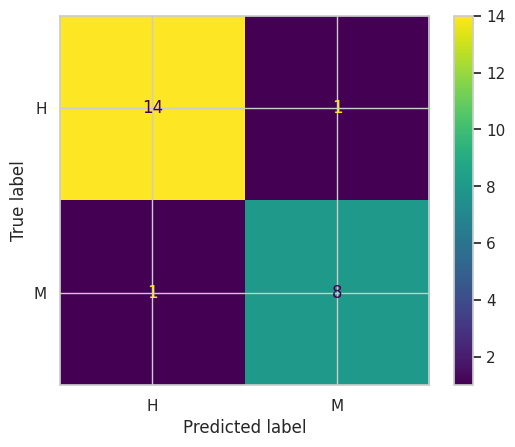

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Select the best model based on Macro F1
best_model_name = results_df.iloc[0]['Model']
print("Best Model:", best_model_name)

# Get predictions from the best model
predictions = {
    'Logistic Regression': lr_pred,
    'KNN': knn_pred,
    'SVM': svm_pred,
    'Decision Tree': dt_pred,
    'Random Forest': rf_pred,
    'Gradient Boosting': gb_pred
}

best_pred = predictions[best_model_name]

# Classification report
print(classification_report(y_valid, best_pred, zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_valid, best_pred, labels=['H', 'M'])
ConfusionMatrixDisplay(cm, display_labels=['H', 'M']).plot()
plt.show()

## 11. Cross-validation

In [ ]:

from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf", class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, min_samples_leaf=3, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.03, max_depth=2, random_state=42)
}

results = []

for name, model in models.items():
    macro_scores = []
    weighted_scores = []
    f1_m_scores = []

    for train_idx, valid_idx in cv.split(X, y):
        X_tr, X_val = X.iloc[train_idx], X.iloc[valid_idx]
        y_tr, y_val = y.iloc[train_idx], y.iloc[valid_idx]

        # Fit imputer using only the fold's training data
        imputer_cv = SimpleImputer(strategy="median")
        X_tr_imp = imputer_cv.fit_transform(X_tr)
        X_val_imp = imputer_cv.transform(X_val)

        # Scale data for Logistic Regression, KNN and SVM
        if name in ["Logistic Regression", "KNN", "SVM"]:
            scaler_cv = StandardScaler()
            X_tr_imp = scaler_cv.fit_transform(X_tr_imp)
            X_val_imp = scaler_cv.transform(X_val_imp)

        model_cv = clone(model)
        model_cv.fit(X_tr_imp, y_tr)
        pred = model_cv.predict(X_val_imp)

        macro_scores.append(f1_score(y_val, pred, average="macro", zero_division=0))
        weighted_scores.append(f1_score(y_val, pred, average="weighted", zero_division=0))
        f1_m_scores.append(f1_score(y_val, pred, pos_label="M", average="binary", zero_division=0))

    results.append({
        "Model": name,
        "CV Macro F1 Mean": np.mean(macro_scores),
        "CV Macro F1 Std": np.std(macro_scores),
        "CV Weighted F1 Mean": np.mean(weighted_scores),
        "CV F1 (M) Mean": np.mean(f1_m_scores)
    })

cv_results = pd.DataFrame(results).sort_values(
    "CV Macro F1 Mean", ascending=False
).reset_index(drop=True)

display(cv_results.round(4))


,Model,CV Macro F1 Mean,CV Macro F1 Std,CV Weighted F1 Mean,CV F1 (M) Mean
0,KNN,0.8882,0.1011,0.8924,0.8693
1,SVM,0.8675,0.1046,0.8720,0.8478
2,Random Forest,0.8643,0.1057,0.8711,0.8358
3,Logistic Regression,0.8643,0.0869,0.8707,0.8378
4,Gradient Boosting,0.8155,0.1449,0.8270,0.7701
5,Decision Tree,0.7653,0.1337,0.7788,0.7105


In [ ]:
knn_results = []

for k in [3, 5, 7, 9, 11, 13, 15, 17, 19, 21]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)

    pred = knn.predict(X_valid_scaled)

    knn_results.append({
        "K": k,
        "Macro F1": f1_score(
            y_valid, pred, average="macro", zero_division=0
        )
    })

knn_results_df = pd.DataFrame(knn_results)
display(knn_results_df.sort_values("Macro F1", ascending=False))

,K,Macro F1
0,3,0.911111
1,5,0.911111
8,19,0.911111
9,21,0.911111
2,7,0.863378
3,9,0.863378
5,13,0.863378
4,11,0.863378
7,17,0.863378
6,15,0.863378


### 12. Fit the selected model on all training rows

In [ ]:
print("X_train_scaled:", X_train_scaled.shape)
print("y:", y.shape)
print("X:", X.shape)
print("Total target labels:", len(y))

X_train_scaled: (70, 18)
y: (94,)
X: (94, 18)
Total target labels: 94


In [ ]:
# Transform all training data using your existing imputer and scaler
X_imputed = imputer.transform(X)
X_scaled = scaler.transform(X_imputed)

# Train the final KNN model
from sklearn.neighbors import KNeighborsClassifier

final_model = KNeighborsClassifier(n_neighbors=5)
final_model.fit(X_scaled, y)

print("Final KNN model trained successfully!")
print("Training features:", X_scaled.shape)
print("Target labels:", y.shape)

Final KNN model trained successfully!
Training features: (94, 18)
Target labels: (94,)


## 14. Load test.csv

In [ ]:
import pandas as pd

test_df = pd.read_csv('/content/drive/MyDrive/DSA/kaggle casestudy dataset/test.csv')

print("Test dataset shape:", test_df.shape)
display(test_df.head())

Test dataset shape: (41, 13)


,id,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
0,A70_2018,183.57,117.18,87.90,53.60,33.10,26.50,95.70,52.5,98.6,104.4,208.8,3.35
1,5C9_2018,166.60,105.05,80.63,51.64,31.31,26.10,88.82,50.7,93.4,101.4,202.8,2.43
2,5E1_2018,175.53,111.23,84.93,53.74,32.75,24.93,91.42,51.3,94.2,103.4,206.8,2.99
3,C58_2018,187.85,116.90,87.52,54.22,35.10,27.00,99.48,52.3,99.8,107.6,215.2,3.55
4,5E2_2018,182.67,116.40,87.24,54.57,33.59,25.40,96.43,53.4,100.3,110.1,220.2,3.06


Test dataset shape: (41, 13)


,id,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
0,A70_2018,183.57,117.18,87.90,53.60,33.10,26.50,95.70,52.5,98.6,104.4,208.8,3.35
1,5C9_2018,166.60,105.05,80.63,51.64,31.31,26.10,88.82,50.7,93.4,101.4,202.8,2.43
2,5E1_2018,175.53,111.23,84.93,53.74,32.75,24.93,91.42,51.3,94.2,103.4,206.8,2.99
3,C58_2018,187.85,116.90,87.52,54.22,35.10,27.00,99.48,52.3,99.8,107.6,215.2,3.55
4,5E2_2018,182.67,116.40,87.24,54.57,33.59,25.40,96.43,53.4,100.3,110.1,220.2,3.06


In [ ]:
test_fe = test_df.copy()

test_fe['beak_to_skull_ratio'] = test_fe['longitudPico'] / test_fe['longitudCraneo']
test_fe['beak_height_ratio'] = test_fe['altoPico'] / test_fe['longitudPico']
test_fe['beak_width_ratio'] = test_fe['anchoPico'] / test_fe['longitudPico']
test_fe['wing_ratio'] = test_fe['longAlaAbierta'] / test_fe['longAlaCerrada']
test_fe['mass_to_skull_ratio'] = test_fe['peso'] / test_fe['longitudCraneo']

In [ ]:
# Remove difference from training features
X_clean = X.drop(columns=['difference'], errors='ignore')

# Check the columns
print("Training feature shape:", X_clean.shape)
print("Contains difference:", 'difference' in X_clean.columns)

Training feature shape: (94, 17)
Contains difference: False


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

imputer_final = SimpleImputer(strategy='median')
X_clean_imputed = imputer_final.fit_transform(X_clean)

scaler_final = StandardScaler()
X_clean_scaled = scaler_final.fit_transform(X_clean_imputed)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

final_model = KNeighborsClassifier(n_neighbors=5)
final_model.fit(X_clean_scaled, y)

print("Final KNN model trained successfully!")

Final KNN model trained successfully!


In [ ]:
X_test = test_fe[X_clean.columns]

X_test_imputed = imputer_final.transform(X_test)
X_test_scaled = scaler_final.transform(X_test_imputed)

print("Test features ready:", X_test_scaled.shape)

Test features ready: (41, 17)


In [ ]:
test_predictions = final_model.predict(X_test_scaled)

print("First 10 predictions:", test_predictions[:10])
print("Total predictions:", len(test_predictions))

First 10 predictions: ['M' 'H' 'M' 'M' 'M' 'M' 'M' 'M' 'M' 'M']
Total predictions: 41


In [ ]:
submission = pd.DataFrame({
    'id': test_df['id'],
    'sexo': test_predictions
})

display(submission.head())

print("Submission shape:", submission.shape)

submission.to_csv('submission.csv', index=False)

print("Submission file created successfully!")

,id,sexo
0,A70_2018,M
1,5C9_2018,H
2,5E1_2018,M
3,C58_2018,M
4,5E2_2018,M


Submission shape: (41, 2)
Submission file created successfully!


In [ ]:
from google.colab import files

files.download('submission.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


- **Final Model:** K-Nearest Neighbors (KNN)
- **Number of Neighbors (`n_neighbors`):** 5
- **Competition Score:** 0.9444

### Final Outcome
Successfully trained the KNN classification model, generated predictions for the test dataset, and submitted the `submission.csv` file to the competition.

**Final competition score: 0.9444**